# Extending NIFE

NIFE is organized by **kind of explanation** — today, counterfactual explanations (`nife.counterfactual`) — each with the **methods** that produce it, the **metrics** that evaluate it and the **plots** that show it. New methods, metrics, plots and kinds of explanation plug into the same structure. [CONTRIBUTING.md](../CONTRIBUTING.md) describes how the code is organized and how to propose a change.

The examples of this notebook use a random forest that classifies wines. Requirements: `pip install "nife-xai[notebooks]"`.

In [1]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier

from nife.counterfactual import TreeCounterfactualExplainer

X, y = load_wine(return_X_y=True, as_frame=True)
model = RandomForestClassifier(random_state=0).fit(X, y)

## A new counterfactual method

A new counterfactual method derives from `CounterfactualExplainer` and only finds candidate counterfactuals. The base class confirms them with the model, enforces the desired outcome and the immutable features, measures, ranks and selects them, finds their counterparts and evaluates them. `_search` returns the candidates (the feature columns and `source`) and a dict of extra fields for the method's explanation, a subclass of `CounterfactualExplanation` set as `explanation_type`:

In [2]:
from nife.counterfactual import CounterfactualExplainer


class NearestExamples(CounterfactualExplainer):
    """Every example of the data is a candidate; the closest valid ones win."""

    def _search(self, x, prediction, desired, rng):
        return self.data.assign(source="data"), {}  # candidates and extra fields of the explanation


NearestExamples(model, X).explain(X.iloc[0], max_counterfactuals=3)

CounterfactualExplanation (classification) of an instance predicted 0
  counterfactuals: 3, changing 13 features each (data: 3)
  closest: alcohol 14.23 -> 13.11, malic_acid 1.71 -> 1.01, ash 2.43 -> 1.7 and 10 more; predicted 1 (distance 0.176; counterpart at distance 0.000)

## A new metric

A new metric is a function of an `EvaluationContext`, registered once with `register_metric`; [evaluation.ipynb](counterfactual/evaluation.ipynb#New-metrics) shows an example.

## A new plot

A new plot is a method named `plot_<kind>` that takes an optional `ax` and returns the Axes. `plot("<kind>")` and `plot_kinds()` find it, and subclasses inherit it. The helpers of `nife.plotting` give it the look of the other plots:

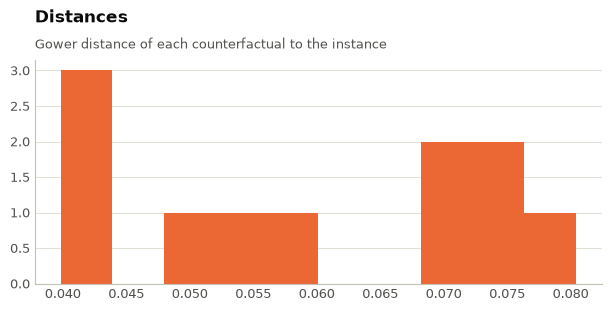

In [3]:
from nife.counterfactual import TreeCounterfactualExplanation
from nife.plotting import COLORS, clean_axes, new_axes, set_titles, styled


class MyExplanation(TreeCounterfactualExplanation):
    def plot_distances(self, *, ax=None):   # a new kind of plot: "distances"
        """Distance of each counterfactual to the instance."""
        return _plot_distances(self, ax)


@styled
def _plot_distances(explanation, ax):
    ax = new_axes(ax, figsize=(6, 3))
    ax.hist(explanation.counterfactuals["distance"], color=COLORS["counterfactual"])
    clean_axes(ax, grid="y")
    set_titles(ax, "Distances", "Gower distance of each counterfactual to the instance")
    return ax


class MyExplainer(TreeCounterfactualExplainer):
    explanation_type = MyExplanation   # explain returns MyExplanation


MyExplainer(model, X).explain(X.iloc[0]).plot("distances");

## A new kind of explanation

A new kind of explanation is a new subpackage next to `nife.counterfactual`, with its methods, metrics and plots. Its explainers derive from `nife.base.Explainer` and its explanations from `nife.base.Explanation`, so the explanations get `plot()` and `plot_kinds()` and draw in the same style. Shared tools, such as the Gower distance (`nife.distance`) and the look of the plots (`nife.plotting`), stay at the top level.

## Documenting it

The notebooks follow the same structure as the code:

- a kind of explanation has a folder in `notebooks/`, with a notebook for what its methods have in common (for counterfactuals, [counterfactual_explanations.ipynb](counterfactual/counterfactual_explanations.ipynb));
- a method has a notebook in that folder, named after its class, such as [TreeCounterfactualExplainer.ipynb](counterfactual/TreeCounterfactualExplainer.ipynb), and a row in the tables of the README and of the folder's common notebook;
- the notebook of a method ends with how to cite the work that introduced it and its references.

The tests run every notebook from top to bottom, so the notebooks keep working as the code changes. After a change, run them again to update their outputs: `jupyter nbconvert --to notebook --execute --inplace notebooks/<path>.ipynb`.